Imports and Loading the Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual styling
sns.set_theme(style="whitegrid")

# Define columns (unit, cycle, 3 operational settings, 21 sensors)
index_cols = ['unit_number', 'time_cycles']
setting_cols = ['setting_1', 'setting_2', 'setting_3']
sensor_cols = [f'sensor_{i}' for i in range(1, 22)]
columns = index_cols + setting_cols + sensor_cols

# Load data with space separator
train_df = pd.read_csv('data/train_FD001.txt', sep=r'\s+', header=None, names=columns)

print(f"Dataset shape: {train_df.shape}")
print(f"Total engines: {train_df['unit_number'].nunique()}")
train_df.head()

Dataset shape: (20631, 26)
Total engines: 100


,unit_number,time_cycles,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


Calculate Remaining Useful Life (RUL)

In [2]:
# Calculate max cycle per engine
max_cycles = train_df.groupby('unit_number')['time_cycles'].max().reset_index()
max_cycles.rename(columns={'time_cycles': 'max_cycle'}, inplace=True)

# Merge back and compute RUL
train_df = train_df.merge(max_cycles, on='unit_number', how='left')
train_df['RUL'] = train_df['max_cycle'] - train_df['time_cycles']
train_df.drop(columns=['max_cycle'], inplace=True)

print("Engine life distribution (cycles to failure):")
print(max_cycles['max_cycle'].describe())

Engine life distribution (cycles to failure):
count    100.000000
mean     206.310000
std       46.342749
min      128.000000
25%      177.000000
50%      199.000000
75%      229.250000
max      362.000000
Name: max_cycle, dtype: float64


Identify Constant / Flat-Line Sensors

In [3]:
# Check standard deviation of all sensors
sensor_std = train_df[sensor_cols].std()

# Find sensors with standard deviation near 0
flat_sensors = sensor_std[sensor_std < 0.001].index.tolist()

print(f"Constant/flat-line sensors ({len(flat_sensors)} found):")
print(flat_sensors)

Constant/flat-line sensors (6 found):
['sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']


Plot Sensor Trends Over Time

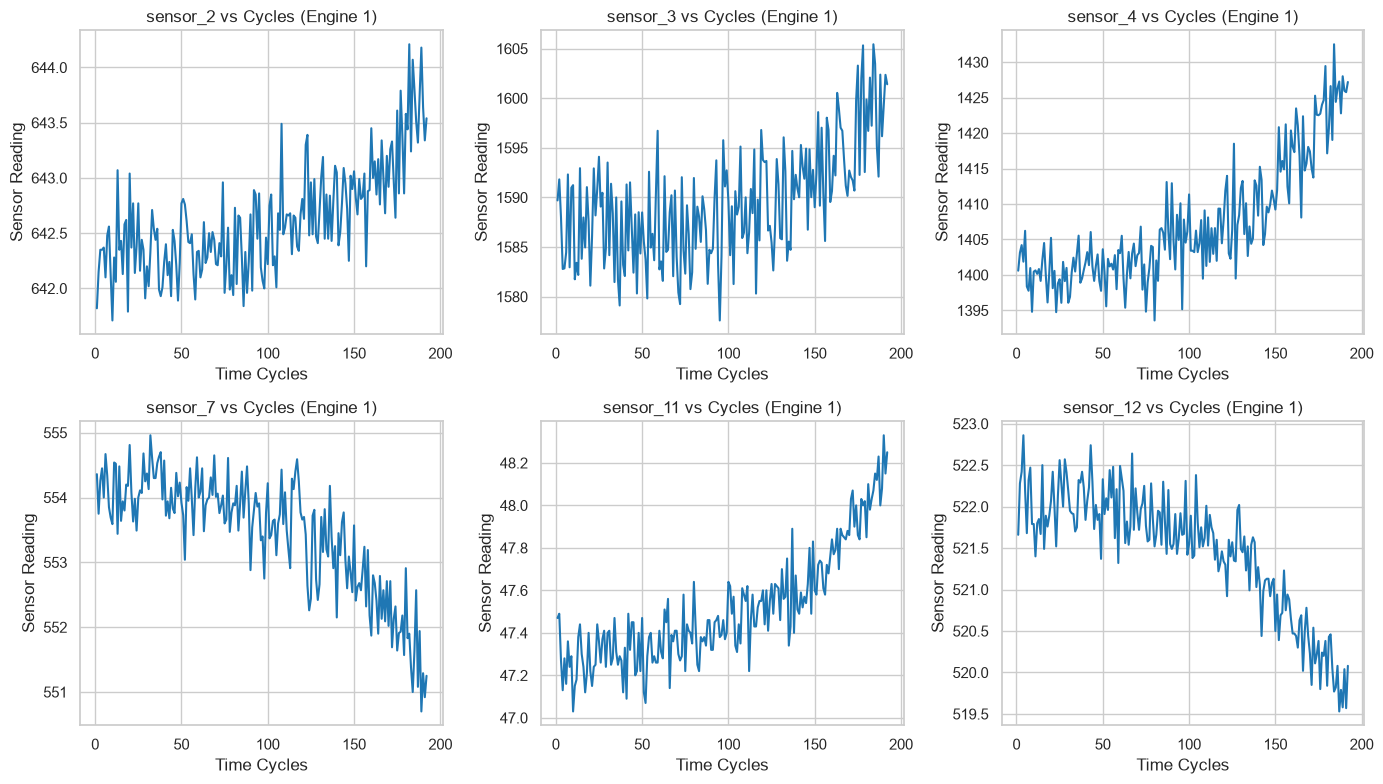

In [4]:
# Select engine #1 to view sensor degradation curves
engine_1 = train_df[train_df['unit_number'] == 1]

# Pick a few active sensors to plot
active_sample = ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_11', 'sensor_12']

plt.figure(figsize=(14, 8))
for i, sensor in enumerate(active_sample, 1):
    plt.subplot(2, 3, i)
    plt.plot(engine_1['time_cycles'], engine_1[sensor], color='tab:blue', lw=1.5)
    plt.title(f"{sensor} vs Cycles (Engine 1)")
    plt.xlabel("Time Cycles")
    plt.ylabel("Sensor Reading")

plt.tight_layout()
plt.show()